# aiodpc, step by step

Every afternoon the Italian Civil Protection Department (DPC) publishes two
bulletins for the whole country: the **alert levels** of today and tomorrow,
and the **weather** of the next three days. They are open data, but they are
large GeoJSON files written in Italian. aiodpc turns them into answers.

This notebook is a lesson that grows like a math class: it starts with a
single yes or no about one place, draws the map of the whole country and ends
with the same notice in six languages.
Along the way it follows a practical story: a network of **community kitchens**
in several Italian cities that wants to warn its volunteers and guests the day
before an alert. The same steps serve a school, a sports club, a parish, a
farm or a town hall.

The outputs below are real: they come from the bulletins of **15 November
2026**. Run the notebook again to see today's.

```bash
pip install "aiodpc[schema]" matplotlib
```

> Data: Dipartimento della Protezione Civile – Presidenza del Consiglio dei
> Ministri, [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). The
> bulletins are official, this notebook is not: for safety decisions, always
> follow the official DPC and regional channels.

Jupyter runs `await` directly in a cell, so one client is enough for the whole
notebook. In a script, use `async with DpcClient() as dpc:` inside an
`async def main()` and `asyncio.run(main())`, as in the
[README](https://github.com/webysther/aiodpc#readme).

In [1]:
from aiodpc import DpcClient

dpc = DpcClient()

## 1. One place, one question

The simplest question has a yes or no answer: *is there an alert here today?*
An alert is any level from yellow up.

In [2]:
rome = dpc.location(41.9, 12.5)

await rome.has_risk()

False

## 2. Which risk, and until when

A no is reassuring, but a yes needs more: which level, which risk, and how
long it lasts. `risk()` answers with the level and the risk types, the summary
DPC writes (in Italian) and the end of its validity.

In [3]:
risk = await rome.risk()

print(risk)
print(risk.description)
print(f"Valid until {risk.valid_until:%d %B %Y %H:%M}")

green
Assenza di fenomeni significativi prevedibili
Valid until 16 November 2026 00:00


## 3. Today and tomorrow

The bulletin is published in the afternoon and also covers the next day, which
is what lets the kitchens warn people in time. Levels are ordered, so they can
be compared: `risk.level >= AlertLevel.YELLOW` is the same as `risk.is_alert`.

In [4]:
from aiodpc import AlertLevel, Day, DpcNoDataError

for day in (Day.TODAY, Day.TOMORROW):
    try:
        risk = await rome.risk(day)
    except DpcNoDataError:  # after midnight, until DPC publishes
        print(f"{day.date():%A %d}: not published yet")
        continue
    print(f"{day.date():%A %d}: {risk}, alert: {risk.level >= AlertLevel.YELLOW}")

Sunday 15: green, alert: False
Monday 16: yellow (hydrogeological), alert: True


Each day also links to the national map DPC draws for it:

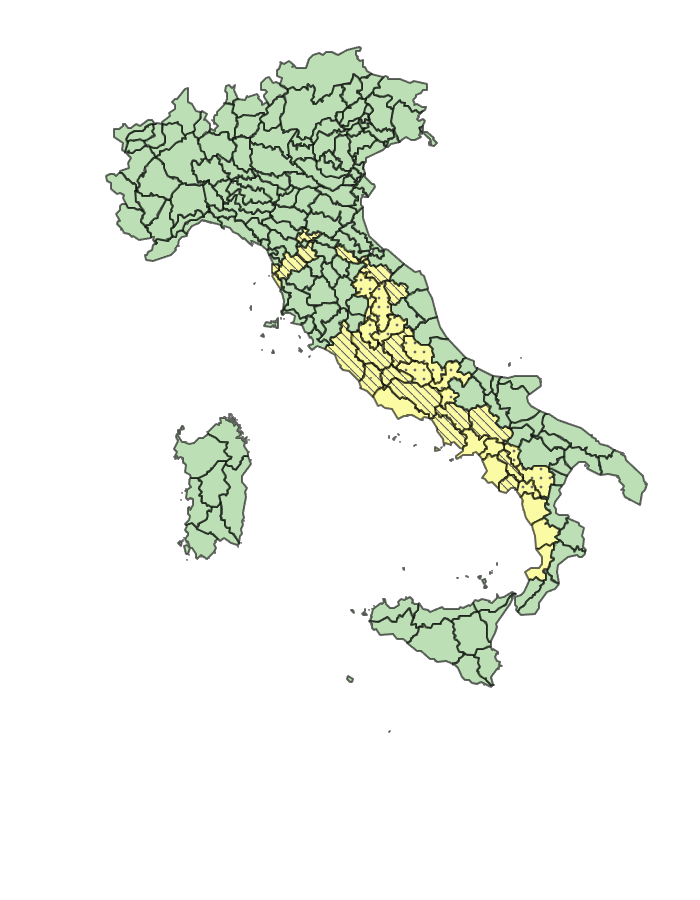

In [5]:
from IPython.display import Image

latest = (await rome.criticality()).days[-1]  # tomorrow, once published
Image(url=latest.image_url, embed=True, width=420)

## 4. The whole day: three risks and the weather

One level per day sums up three assessments: **hydraulic** (the main rivers),
**thunderstorms** and **hydrogeological** (landslides and the minor streams).
The second bulletin, the weather vigilance, adds the expected
**precipitation** and the significant **phenomena** around the place, with
their distance and direction.

In [6]:
from aiodpc import Location

ROME = Location(41.9, 12.5)

alerts = await dpc.get_criticality(ROME)
weather = await dpc.get_vigilance(ROME, phenomena_within_km=30)

for day in alerts:
    print(f"{day.date} {day.zone}: {day.level}")
    for assessment in day.risks:
        print(f"  {assessment.type:<16} {assessment.level:<7} {assessment.description}")

2026-11-15 Bacini di Roma: green
  hydraulic        green   Assenza di fenomeni significativi prevedibili
  thunderstorms    green   Assenza di fenomeni significativi prevedibili
  hydrogeological  green   Assenza di fenomeni significativi prevedibili
2026-11-16 Bacini di Roma: yellow
  hydraulic        green   Assenza di fenomeni significativi prevedibili
  thunderstorms    green   Assenza di fenomeni significativi prevedibili
  hydrogeological  yellow  Ordinaria


In [7]:
for day in weather:
    print(f"{day.date} {day.zone}: {day.precipitation} precipitation")
    for phenomenon in day.phenomena:
        print(
            f"  {phenomenon.type}, {phenomenon.distance_km} km {phenomenon.direction}"
        )

2026-11-15 Comune di Roma: light precipitation
  scattered_rain, 25.2 km SW
2026-11-16 Comune di Roma: light precipitation
  scattered_rain, 20.2 km WNW
2026-11-17 Comune di Roma: light precipitation
  scattered_rain, 27.3 km SE


The levels, risk types and phenomena print as English codes (`yellow`,
`hydrogeological`, `scattered_rain`), ready to translate; the text DPC writes
stays in Italian in `description`.

## 5. Many places, one download

Now the whole network. Each bulletin is a single file for all of Italy, about
18 MB a day for both, so it is downloaded **once** and read at each kitchen
with `at()`, which makes no request. A municipality makes the answer more
precise, since large cities span several zones; and a place outside Italy
simply has no zone.

In [8]:
from aiodpc import DpcLocationError

KITCHENS = {
    "Turin": Location(45.07, 7.69, municipality="Torino"),
    "Milan": Location(45.46, 9.19, municipality="Milano"),
    "Bologna": Location(44.49, 11.34, municipality="Bologna"),
    "Florence": Location(43.77, 11.25, municipality="Firenze"),
    "Rome": Location(41.9, 12.5, municipality="Roma"),
    "Naples": Location(40.85, 14.27, municipality="Napoli"),
    "Palermo": Location(38.12, 13.36, municipality="Palermo"),
    "Lugano": Location(46.0, 8.95),  # Switzerland: no DPC zone
}

criticality = await dpc.get_criticality_map()

for city, place in KITCHENS.items():
    try:
        tomorrow = criticality.at(place).tomorrow
    except DpcLocationError:
        print(f"{city:<9} not covered by DPC")
        continue
    if tomorrow is None:  # after midnight, until DPC publishes
        print(f"{city:<9} not published yet")
        continue
    notice = "send a notice" if tomorrow.is_alert else "-"
    print(f"{city:<9} {tomorrow.level:<7} {notice:<14} {tomorrow.zone}")

Turin     green   -              Pianura Torinese e Colline
Milan     green   -              Nodo Idraulico di Milano
Bologna   green   -              Collina bolognese
Florence  green   -              Arno-Firenze
Rome      yellow  send a notice  Bacini di Roma
Naples    yellow  send a notice  Piana campana, Napoli, Isole e Area vesuviana
Palermo   green   -              Nord-Occidentale e isole Egadi e Ustica
Lugano    not covered by DPC


## 6. The whole country, in numbers

From a list of places to every zone of Italy. Here we go one level down, to
the DPC files themselves (`aiodpc[schema]`): typed objects with every zone,
its municipalities and its shape. `aiodpc.parsers` reads their texts, such as
`"Ordinaria per rischio idrogeologico / ALLERTA GIALLA"`.

In [9]:
import asyncio
from collections import Counter

from aiodpc import BulletinKind, RiskType
from aiodpc.parsers import parse_assessment, parse_criticality_id

bulletin_id = await dpc.latest_bulletin_id(BulletinKind.CRITICALITY)
published = parse_criticality_id(bulletin_id).date()
files = await asyncio.gather(  # both days at once
    dpc.get_criticality_file(bulletin_id, offset=0),
    dpc.get_criticality_file(bulletin_id, offset=1),
)

print(f"Bulletin {bulletin_id}, {len(files[0].features)} alert zones")
for offset, file in enumerate(files):
    levels = Counter(
        parse_assessment(zone.properties.summary).level for zone in file.features
    )
    counts = ", ".join(f"{count} {level}" for level, count in sorted(levels.items()))
    print(f"  day {offset + 1}: {counts}")

Bulletin 20261115_1421, 187 alert zones
  day 1: 157 green, 30 yellow
  day 2: 151 green, 36 yellow


Which risks are behind tomorrow's alerts, and how many municipalities do they
touch?

In [10]:
tomorrow_zones = files[1].features
for risk_type in RiskType:
    # The fields of a zone are named after the risk types
    zones = [
        zone
        for zone in tomorrow_zones
        if parse_assessment(getattr(zone.properties, risk_type)).level.is_alert
    ]
    municipalities = {name for zone in zones for name in zone.properties.municipalities}
    print(f"{risk_type:<16} {len(zones):>3} zones, {len(municipalities):>5} towns")

hydraulic          7 zones,   414 towns
thunderstorms     14 zones,   500 towns
hydrogeological   36 zones,  1537 towns


## 7. The picture: drawing the map

The files carry the shape of each zone, so the numbers become a map. The
colors are the official ones of the alert levels.

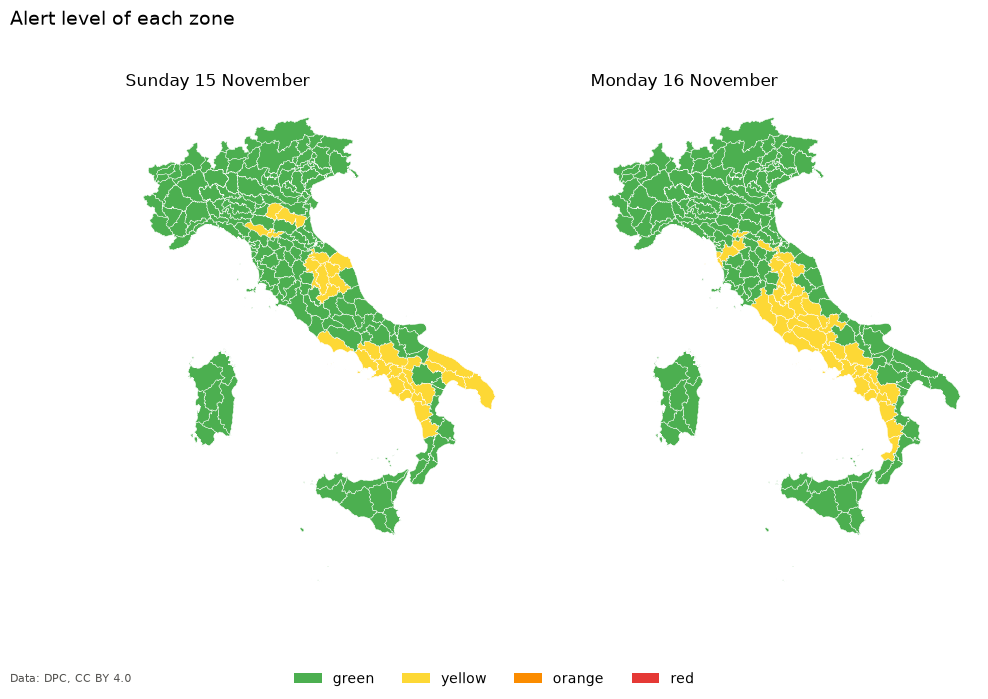

In [11]:
import datetime as dt
from collections.abc import Callable, Sequence

import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from matplotlib.patches import Patch, Polygon

from aiodpc.schema import Geometry, MultiPolygon, Position
from aiodpc.schema import Polygon as ZonePolygon

LEVEL_COLORS = {
    AlertLevel.GREEN: "#4caf50",
    AlertLevel.YELLOW: "#fdd835",
    AlertLevel.ORANGE: "#fb8c00",
    AlertLevel.RED: "#e53935",
    AlertLevel.UNKNOWN: "#bdbdbd",
}
ITALY_ASPECT = 1.35  # 1 / cos(42°): degrees of longitude are shorter in Italy


def outer_rings(geometry: Geometry | None) -> list[list[Position]]:
    """Return the outer ring of each polygon of a zone."""
    if isinstance(geometry, ZonePolygon):
        return [geometry.coordinates[0]]
    if isinstance(geometry, MultiPolygon):
        return [polygon[0] for polygon in geometry.coordinates]
    return []


def draw_zones[Zone](
    axes: Axes, features: Sequence[Zone], color_of: Callable[[Zone], str]
) -> None:
    """Fill each zone with its color, separated by thin white borders."""
    for zone in features:
        for ring in outer_rings(zone.geometry):
            axes.add_patch(
                Polygon(
                    ring, facecolor=color_of(zone), edgecolor="white", linewidth=0.3
                )
            )
    axes.autoscale_view()
    axes.set_aspect(ITALY_ASPECT)
    axes.set_axis_off()


figure, panels = plt.subplots(1, 2, figsize=(11, 7), facecolor="white")
for offset, (axes, file) in enumerate(zip(panels, files, strict=True)):
    date = published + dt.timedelta(days=offset)
    draw_zones(
        axes,
        file.features,
        lambda zone: LEVEL_COLORS[parse_assessment(zone.properties.summary).level],
    )
    axes.set_title(f"{date:%A %d %B}", loc="left")

figure.legend(
    handles=[
        Patch(facecolor=color, label=str(level))
        for level, color in LEVEL_COLORS.items()
        if level is not AlertLevel.UNKNOWN
    ],
    loc="lower center",
    ncols=4,
    frameon=False,
)
figure.suptitle("Alert level of each zone", x=0.02, ha="left", fontsize=14)
figure.text(0.02, 0.02, "Data: DPC, CC BY 4.0", fontsize=8, color="#52514e")
figure.savefig("alert-map.png")  # to share it, e.g. on the kitchens' board
plt.show()

The weather bulletin has its own zones and places each phenomenon on the map.
Here are tomorrow's, by category:

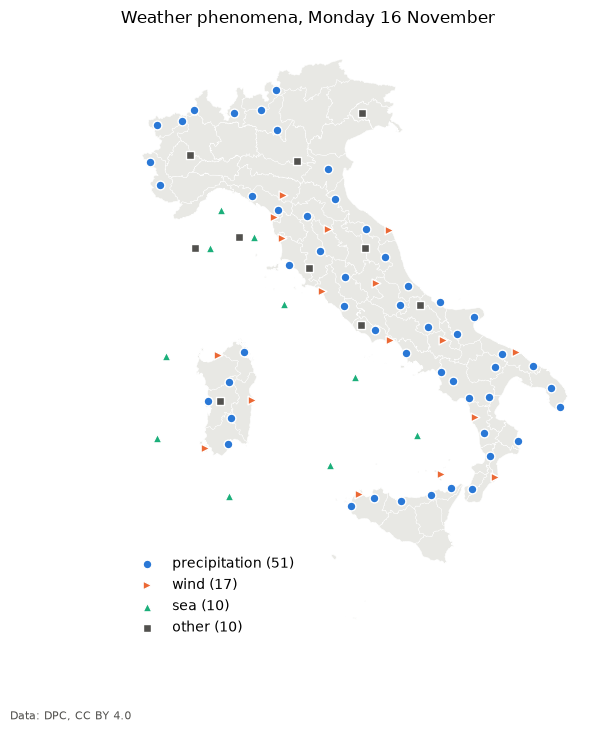

In [12]:
from aiodpc import PhenomenonCategory
from aiodpc.parsers import PHENOMENON_TYPES

vigilance_id = await dpc.latest_bulletin_id(BulletinKind.VIGILANCE)
vigilance_zones = await dpc.get_vigilance_file(vigilance_id, offset=1)
phenomena = await dpc.get_phenomena_file(vigilance_id, offset=1)

# Three categories and the rest: more colors would be hard to tell apart
CATEGORY_STYLES = {
    PhenomenonCategory.PRECIPITATION: ("#2a78d6", "o"),
    PhenomenonCategory.WIND: ("#eb6834", ">"),
    PhenomenonCategory.SEA: ("#1baf7a", "^"),
}
OTHER_STYLE = ("#52514e", "s")

figure, axes = plt.subplots(figsize=(7, 8), facecolor="white")
draw_zones(axes, vigilance_zones.features, lambda _zone: "#e8e8e4")

by_style = {}
for feature in phenomena.features:
    category, _legend = PHENOMENON_TYPES.get(feature.properties.code, (None, None))
    if category not in CATEGORY_STYLES:
        category = None
    by_style.setdefault(category, []).append(feature.properties)

for category, items in by_style.items():
    color, marker = CATEGORY_STYLES.get(category, OTHER_STYLE)
    axes.scatter(
        [item.longitude for item in items],
        [item.latitude for item in items],
        s=40,
        color=color,
        marker=marker,
        edgecolors="white",
        linewidths=1,
        label=f"{category or 'other'} ({len(items)})",
    )

axes.legend(loc="lower left", frameon=False)
date = published + dt.timedelta(days=1)
axes.set_title(f"Weather phenomena, {date:%A %d %B}", loc="left")
figure.text(0.02, 0.02, "Data: DPC, CC BY 4.0", fontsize=8, color="#52514e")
plt.show()

## 8. Keeping watch: telling people in time

Back to one place, with everything learned. The kitchens want a notice ready
the afternoon before an alert. `dpc.location()` keeps its bulletin and
downloads a new one only when DPC publishes it, so it can be asked as often as
needed; a script would ask every 30 minutes in a loop (see the
[README](https://github.com/webysther/aiodpc#6-keeping-watch)).

In [13]:
from aiodpc import Risk


def notice(risk: Risk | None) -> str | None:
    """Return the text to share with volunteers and guests, or None."""
    if risk is None or not risk.is_alert:
        return None
    return (
        f"{risk.day.date:%A %d %B}: {risk.level} alert in {risk.day.zone} "
        f"for {', '.join(risk.types)} risk.\n"
        f"DPC: {risk.description}. Follow the official channels."
    )


for city in ("Rome", "Naples", "Milan"):
    place = KITCHENS[city]
    watched = dpc.location(*place.coordinates, municipality=place.municipality)
    try:
        risk = await watched.risk(Day.TOMORROW)
    except DpcNoDataError:  # after midnight, until DPC publishes
        risk = None
    text = notice(risk)
    print(f"{city}: {text or 'nothing to announce'}")

Rome: Monday 16 November: yellow alert in Bacini di Roma for hydrogeological risk.
DPC: Ordinaria per rischio idrogeologico. Follow the official channels.


Naples: Monday 16 November: yellow alert in Piana campana, Napoli, Isole e Area vesuviana for hydrogeological risk.
DPC: Ordinaria per rischio idrogeologico. Follow the official channels.


Milan: nothing to announce


## 9. Every language

DPC writes in Italian, but the kitchens' volunteers and guests speak many
languages. Every value of the bulletins has a text in English, Italian,
Brazilian Portuguese, French, German and Spanish, the DPC description
included: the same notice, in each of them.

In [14]:
from aiodpc import Language, Translator

rome = dpc.location(41.9, 12.5, municipality="Roma")
try:
    day, risk = Day.TOMORROW, await rome.risk(Day.TOMORROW)
except DpcNoDataError:  # after midnight, until DPC publishes
    day, risk = Day.TODAY, await rome.risk(Day.TODAY)

for language in Language:
    tell = Translator(language)
    print(f"{language:<6} {tell(day)}: {tell.risk(risk)}.")
    print(f"       DPC: {tell.description(risk)}.")

en     Tomorrow: Yellow alert for hydrogeological risk.
       DPC: Ordinary criticality for hydrogeological risk.
it     Domani: Allerta gialla per rischio idrogeologico.
       DPC: Ordinaria per rischio idrogeologico.
pt-BR  Amanhã: Alerta amarelo para risco hidrogeológico.
       DPC: Criticidade ordinária para risco hidrogeológico.
fr     Demain: Alerte jaune pour risque hydrogéologique.
       DPC: Criticité ordinaire pour risque hydrogéologique.
de     Morgen: Gelbe Warnung für hydrogeologisches Risiko.
       DPC: Geringes Gefährdungspotenzial für hydrogeologisches Risiko.
es     Mañana: Alerta amarilla por riesgo hidrogeológico.
       DPC: Criticidad ordinaria por riesgo hidrogeológico.


The weather too: the precipitation and the phenomena around Rome from step 4,
with the decimal separator and the compass points of the language.

In [15]:
tell = Translator("pt-BR")

precipitation = tell(PhenomenonCategory.PRECIPITATION)
for day in weather:
    print(f"{day.date}: {precipitation} {tell(day.precipitation).lower()}")
    for phenomenon in day.phenomena:
        print(f"  {tell.phenomenon(phenomenon)}")

2026-11-15: Precipitação fraca
  Chuvas esparsas ou intermitentes, 25,2 km SO
2026-11-16: Precipitação fraca
  Chuvas esparsas ou intermitentes, 20,2 km ONO
2026-11-17: Precipitação fraca
  Chuvas esparsas ou intermitentes, 27,3 km SE


In [16]:
await dpc.close()

## Where to go next

- The [README](https://github.com/webysther/aiodpc#readme) has the reference:
  days and validity, municipalities, errors, the low-level API.
- [DPC Alert](https://github.com/caiosweet/Home-Assistant-custom-components-DPC-Alert)
  brings the same data to Home Assistant, with a ready-made dashboard.